<a href="https://colab.research.google.com/github/TlameloPatlakwe/AI-for-S-E-Projects/blob/main/Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Statistical Analysis of Geotechnical Data for Slope Stability Prediction**

This notebook explores the statistical characteristics and relationship between the selected geotechnical parameters and the FoS of a heterogeneous slope

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

df = pd.read_excel(next(iter(uploaded)))

df.head()


Saving MAIN DATASET (1).xlsx to MAIN DATASET (1).xlsx


,CASE,COMPRESSIVE STRENGTH(KIMBERLITE),mb,s,a,COMPRESSIVE STRENGTH(CS),mb.1,s.1,a.1,COMPRESSIVE STRENGTH(DOLOMITE),...,s.4,a.4,TENSILE STRENGTH(SAND),FRICTION ANGLE,COHESION,TENSILE STRENGTH(CALCRETE),FRICTION ANGLE.1,COHESION.1,RU,FoS
0,1,36064.238781,1.917204,0.004320,0.510723,119041.677640,0.530627,0.001319,0.526136,289562.638924,...,0.000819,0.502310,1,33.738229,1,1,29.868210,1,0.075,1.15
1,2,31972.366503,1.521989,0.003706,0.482796,159679.036671,0.536456,0.001330,0.530334,349270.527018,...,0.000677,0.521358,1,35.070238,1,1,31.408754,1,0.075,1.16
2,3,49284.275233,1.866600,0.003728,0.527070,112964.325185,0.546670,0.001301,0.498686,254765.340051,...,0.001190,0.497564,1,36.104115,1,1,30.813811,1,0.075,1.16
3,4,35688.098048,1.161285,0.004989,0.511970,134780.822237,0.493544,0.001742,0.498678,310609.492012,...,0.000905,0.509303,1,33.627620,1,1,29.443068,1,0.075,1.15
4,5,48537.055490,1.282094,0.003034,0.518658,125591.834894,0.498928,0.001702,0.490356,343384.475454,...,0.000723,0.493015,1,34.744877,1,1,28.520856,1,0.075,1.46


In [2]:

variables = [
    'COHESION',
    'FRICTION ANGLE',
    'RU',
    'FoS'
]

data = df[variables].copy()

data.head()


,COHESION,FRICTION ANGLE,RU,FoS
0,1,33.738229,0.075,1.15
1,1,35.070238,0.075,1.16
2,1,36.104115,0.075,1.16
3,1,33.627620,0.075,1.15
4,1,34.744877,0.075,1.46


In [3]:

statistics = pd.DataFrame({
    'Mean': data.mean(),
    'Median': data.median(),
    'Range': data.max() - data.min(),
    'Variance': data.var(),
    'Standard Deviation': data.std()
})

statistics.round(4)


,Mean,Median,Range,Variance,Standard Deviation
COHESION,1.0000,1.0000,0.000,0.0000,0.0000
FRICTION ANGLE,35.1276,35.2843,3.352,0.9775,0.9887
RU,0.1558,0.1000,0.175,0.0052,0.0718
FoS,1.0584,1.0400,1.020,0.1004,0.3169


In [4]:

covariance = data['RU'].cov(data['FoS'])
correlation = data['RU'].corr(data['FoS'])

print("Covariance:", round(covariance, 4))
print("Correlation:", round(correlation, 4))


Covariance: -0.0215
Correlation: -0.9463


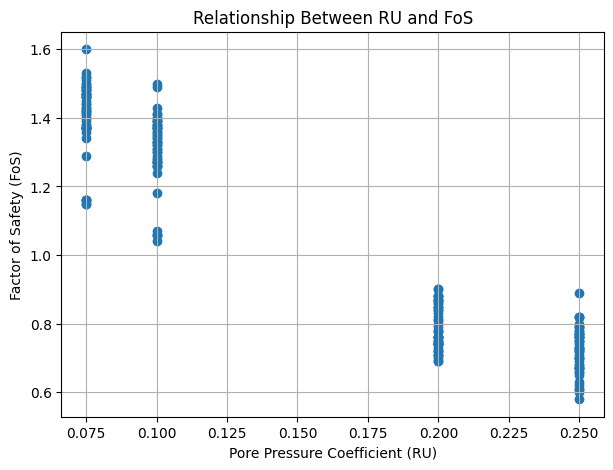

In [5]:

plt.figure(figsize=(7, 5))

plt.scatter(data['RU'], data['FoS'])

plt.xlabel('Pore Pressure Coefficient (RU)')
plt.ylabel('Factor of Safety (FoS)')
plt.title('Relationship Between RU and FoS')

plt.grid(True)
plt.show()


**Results Interpretation**

**What do the statistics tell you about your data?**

The descriptive statistics show variations in the geotechnical parameters and Factor of Safety (FoS). Cohesion remained constant at 1.0, while the friction angle showed relatively low variability, with a mean of 35.1276° and standard deviation of 0.9887°. RU had a mean of 0.1558, while FoS had a mean of
1.0584 and standard deviation of
0.3169, indicating considerable variation in slope stability across the simulated cases.

**What does the correlation tell you about the relationship between the two variables?**

The correlation coefficient of -0.9463 indicates a very strong negative linear relationship between RU and FoS. As RU increases, FoS generally decreases, suggesting that higher pore pressure conditions are associated with reduced slope stability.

**Does correlation necessarily mean that one variable causes the other?**


No. Correlation indicates an association between variables but does not establish causation. Although increasing pore pressure can reduce effective stress and shear resistance, the observed relationship alone does not prove causation, since other geotechnical factors may also influence FoS.

**Mathematical Representation**

Input: Pore Pressure Coefficient (RU)

Output: Factor of Safety (FoS)

$$ RU \rightarrow f(RU) \rightarrow FoS $$


$f$ represents a mathematical or machine learning model that estimates FoS from RU.